       accuracy  precision  recall  specificity      f1  roc_auc
image    0.9494     0.9330  0.9668       0.9324  0.9496   0.9904
freq     0.8440     0.8493  0.8313       0.8563  0.8402   0.9222
both     0.9433     0.9425  0.9426       0.9440  0.9426   0.9872
avg      0.9414     0.9271  0.9565       0.9267  0.9415   0.9818
image vs both (only_image_right, only_both_right, p): (559, 439, np.float64(0.00016256267415370621))
image 12 epochs ran
freq 12 epochs ran
both 12 epochs ran


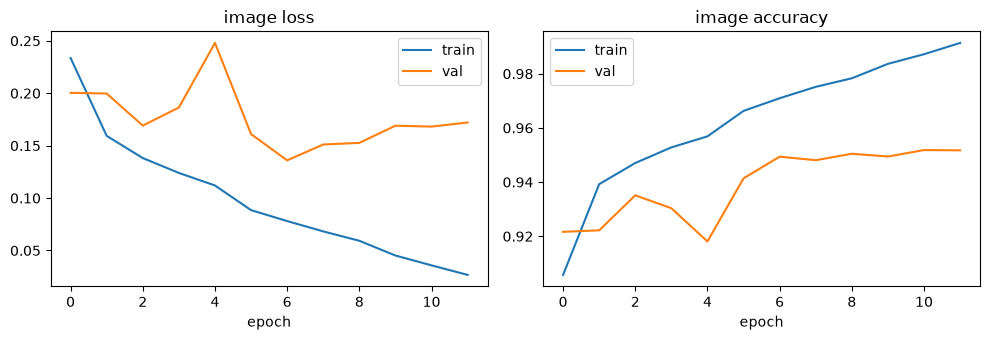

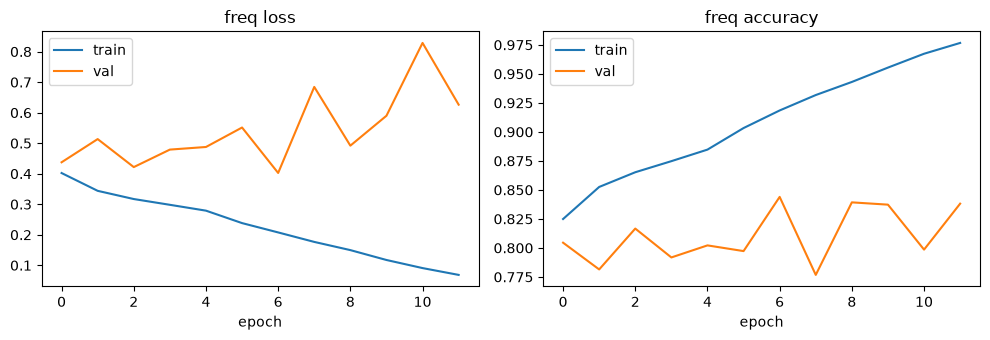

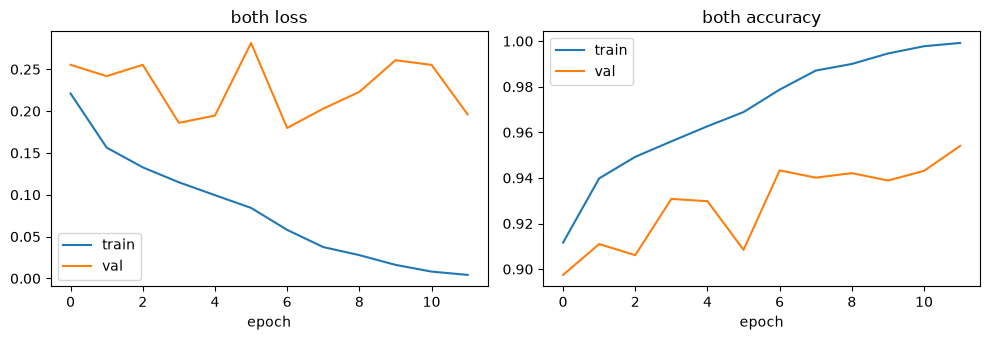

In [1]:
import json
import keras
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import binomtest

from fftdeep.evaluation.metrics import binary_metrics, plot_history
from fftdeep.paths import PROJECT_ROOT
from fftdeep.training.train_fusion import make_inputs

probs, rows = {}, {}
for mode in ["image", "freq", "both"]:
    model = keras.models.load_model(PROJECT_ROOT / "models" / f"cnn_{mode}.keras", compile=False)
    inputs, y = make_inputs(mode, "val")
    probs[mode] = model.predict(inputs, batch_size=512, verbose=0).ravel()
    rows[mode] = binary_metrics(y, probs[mode])

probs["avg"] = (probs["image"] + probs["freq"]) / 2     # late fusion, no extra training
rows["avg"] = binary_metrics(y, probs["avg"])
print(pd.DataFrame(rows).T[["accuracy", "precision", "recall", "specificity", "f1", "roc_auc"]].round(4))

def mcnemar(a, b):
    ok_a = (probs[a] >= 0.5) == (y == 1)
    ok_b = (probs[b] >= 0.5) == (y == 1)
    only_a, only_b = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    return only_a, only_b, binomtest(only_b, only_a + only_b, 0.5).pvalue

print("image vs both (only_image_right, only_both_right, p):", mcnemar("image", "both"))

for mode in ["image", "freq", "both"]:
    h = json.loads((PROJECT_ROOT / "reports" / f"history_{mode}.json").read_text())
    print(mode, len(h["loss"]), "epochs ran")
    plot_history(h, mode)
plt.show()